# S1 · Government collapse: effect per unit of shock, estimated on the EU panel

**What this notebook does.** It estimates how trust moves after a government falls, using **every EU country and every Eurobarometer wave from 2005 to 2025**, not a handful of hand-picked cases. The result is an **effect per unit of shock** with a 90% range, which the dashboard multiplies by the sliders and adds to France's baseline. Method and rules follow the *MVP data specification* and the *Addendum for Mark* (21 Nov 2026).

**One rule (Addendum, point 1): a case that is read or tested is never used to estimate.**
- Every effect is estimated **without France**.
- France's own falls (Barnier, Dec 2024; Bayrou, Sep 2025) are an **out-of-sample check** (section 7).
- The back-test is **leave-one-out**: each past episode is predicted by a model that never saw its country (section 8).

**How to read it.** A change smaller than **about ±4.4 points** (the noise between two Eurobarometer waves of 1,000 people) is reported as *no detectable change*, not as a direction. Everything here is an interpretation, not a prediction: *if a shock like this hit France, past European episodes suggest effects within this range.*

This notebook replaces the earlier side-by-side comparison of 8 episodes (still in the git history). Its case reviews are reused here: the event dates and which endings count as a fall come from `data/reference/s1_verified_events.csv` and `s1_researched_dates.csv`, via `data/processed/s1_all_endings_dataset.csv`.

In [1]:
import sys, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'outputs/model'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30, 'display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BLUE, GREY, RED, LIGHT = '#2b6cb0', '#8a8f98', '#c53030', '#e8ecf1'

NOISE = 4.4          # points: 95% noise on a change between two waves of ~1,000 respondents
HORIZONS = [1, 2, 3, 4]   # Eurobarometer waves after the fall (about 6 months apart)
OUTCOMES = {'trust_gov': 'Trust in government', 'trust_parl': 'Trust in parliament',
            'trust_parties': 'Trust in political parties', 'swd': 'Satisfied with democracy'}
HELD_OUT = 'FRA'

## 1. The shock and the rule that defines it

**Rule (published, not ours):** a *government collapse* is the early end of a cabinet through a break-up of the coalition or a lost parliamentary vote. PPEG codes why each cabinet ended (`Diss` = dissension, `LoPS` = lack of parliamentary support); the team's case reviews then dated each fall and dropped the endings that were not real falls. **Who set it:** PPEG's coding, applied by the team's case review (15 Nov 2026). No threshold is chosen by us for S1.

| Counted as S1 (the shock) | Kept as a control (another cabinet change) | Left out |
| --- | --- | --- |
| Reviewed collapses, incl. those during a scandal or the financial crisis (cause-agnostic, as in CPDS codes 4–5) and dissension cases the review judged a fall | Prime-minister resignations, head-of-state interventions, dissension cases the review judged *not* a fall | Failed government formations (no cabinet ended) |

**The three sliders** (specification, section 3):

| Slider | Measured as | Source |
| --- | --- | --- |
| Days without a full-powered government | Days from the fall to the next cabinet not coded caretaker or expert | PPEG, team review |
| Cabinet falls in the last 24 months | Early cabinet endings in the 24 months before | PPEG |
| Ends with an early election | A parliamentary election within 365 days of the fall | PPEG |

In [2]:
endings = pd.read_csv(ROOT / 'data/processed/s1_all_endings_dataset.csv', parse_dates=['event_date'])
CONFLICT_GROUPS = {'government collapse', 'collapse after a scandal', 'collapse in a financial crisis'}
endings['s1_fall'] = (endings.case_group.isin(CONFLICT_GROUPS)
                      | ((endings.case_group == 'PPEG: cabinet dissension') & (endings.s1_status == 'include')))
endings['other_change'] = ~endings.s1_fall & (endings.case_group != 'failed government formation')
endings['days_no_gov'] = endings.days_until_non_caretaker_cabinet
endings['falls_24m'] = endings.early_endings_24m_before
endings['early_election'] = (endings.next_election_gap_days <= 365).astype(float)

falls = endings[endings.s1_fall].copy()
missing_days = falls.days_no_gov.isna()
falls.loc[missing_days, 'days_no_gov'] = falls.days_no_gov.median()   # one case; flagged below

TYPICAL = {'days': float(falls.loc[falls.iso3 != HELD_OUT, 'days_no_gov'].median()), 'early': 0, 'falls24': 1}
print(f"S1 falls: {len(falls)} in {falls.iso3.nunique()} countries, {falls.event_date.min():%b %Y} to {falls.event_date.max():%b %Y}")
print(f"  of which France (held out): {(falls.iso3 == HELD_OUT).sum()}; used to estimate: {(falls.iso3 != HELD_OUT).sum()}")
print(f"Other cabinet changes kept as a control: {endings.other_change.sum()}")
if missing_days.any():
    print('Days without government imputed (median) for:', ', '.join(falls.loc[missing_days, 'episode_id']))
display(falls[['days_no_gov', 'falls_24m', 'early_election']].describe().loc[['count', 'mean', '50%', 'min', 'max']].round(1)
        .rename(columns={'days_no_gov': 'Days without full government', 'falls_24m': 'Falls in prior 24 months',
                         'early_election': 'Early election (share)'}))

S1 falls: 42 in 23 countries, Feb 2006 to Jun 2025
  of which France (held out): 1; used to estimate: 41
Other cabinet changes kept as a control: 89
Days without government imputed (median) for: NLD_202506_Schoof


,Days without full government,Falls in prior 24 months,Early election (share)
count,42.0,42.0,42.0
mean,134.2,0.9,0.6
50%,48.0,1.0,1.0
min,1.0,0.0,0.0
max,759.0,3.0,1.0


## 2. The panel: every EU country in every wave

Trust and satisfaction with democracy come from `data/processed/eb_panel.csv` (built from the GESIS respondent files by `src/build_eb_panel.py`; it matches the published Eurobarometer figures within rounding). Each row is one country in one wave; a country enters while it is an EU member. A fall is assigned to the **first wave whose fieldwork centre comes after it**; horizon *h* = 1 is that wave, *h* = 2 the next, and so on.

**Controls** (specification, section 2): unemployment, GDP growth and inflation in the year before the wave (Eurostat); the trust trend over the previous wave (catches a slide that was already under way); other cabinet changes in the same interval; country and wave fixed effects. *Months to the next scheduled election* is not in yet: it needs constitutional term lengths per country.

In [3]:
panel = pd.read_csv(ROOT / 'data/processed/eb_panel.csv', parse_dates=['fieldwork_median'])
with zipfile.ZipFile(ROOT / 'data/raw/ppeg_2025v1/ppeg_gov_2025v1.zip') as z:
    members = pd.read_csv(z.open('ppeg_gov_2025v1.csv'), low_memory=False, usecols=['iso3c', 'iso2c', 'eu_since', 'eu_exit']).drop_duplicates('iso3c')
members = members[members.eu_since.notna()]
iso3_of = dict(zip(members.iso2c, members.iso3c))
panel['iso3'] = panel.country.map(iso3_of)
panel = panel.merge(members[['iso3c', 'eu_since', 'eu_exit']], left_on='iso3', right_on='iso3c', how='inner')
yr = panel.fieldwork_median.dt.year
panel = panel[(yr >= panel.eu_since) & (panel.eu_exit.isna() | (yr < panel.eu_exit))]

macro = pd.read_csv(ROOT / 'data/processed/eurostat_macro_country_year.csv')
macro['country'] = macro.geo.replace({'EL': 'GR', 'UK': 'GB'})
macro = macro.rename(columns={'nama_10_gdp_real_growth': 'growth', 'une_rt_a_unemployment': 'unemployment', 'prc_hicp_aind_inflation': 'inflation'})
panel['macro_year'] = yr - 1
panel = panel.merge(macro[['country', 'year', 'growth', 'unemployment', 'inflation']],
                    left_on=['country', 'macro_year'], right_on=['country', 'year'], how='left')
panel = panel.sort_values(['iso3', 'fieldwork_median']).reset_index(drop=True)

START = pd.Timestamp('2005-03-01')   # first wave after which falls are coded (reviewed endings start in 2005)
print(f"{panel.iso3.nunique()} countries, {panel.za.nunique()} waves, {len(panel)} country-waves; estimation uses waves from {START:%b %Y}")

28 countries, 56 waves, 1409 country-waves; estimation uses waves from Mar 2005


In [4]:
_SAMPLES = {}
def build_sample(outcome, h, exclude=(HELD_OUT,)):
    # One row per country-wave k: change in the outcome from wave k-1 to wave k+h-1, the falls between waves k-1 and k.
    if (outcome, h) not in _SAMPLES:
        _SAMPLES[(outcome, h)] = _build_sample(outcome, h)
    s = _SAMPLES[(outcome, h)]
    return s[~s.iso3.isin(exclude)].reset_index(drop=True)

def _build_sample(outcome, h):
    rows = []
    for iso3, d in panel[panel[outcome + '_pct'].notna()].groupby('iso3'):
        d = d.reset_index(drop=True)
        y, t = d[outcome + '_pct'].to_numpy(), d.fieldwork_median.to_numpy()
        for k in range(2, len(d) - h + 1):
            if t[k] < START:
                continue
            ev = falls[(falls.iso3 == iso3) & (falls.event_date > t[k - 1]) & (falls.event_date <= t[k])]
            oc = endings[(endings.iso3 == iso3) & endings.other_change & (endings.event_date > t[k - 1]) & (endings.event_date <= t[k])]
            rows.append({'iso3': iso3, 'wave': d.za[k], 'date': t[k], 'dy': y[k + h - 1] - y[k - 1],
                         'pre_trend': y[k - 1] - y[k - 2], 'placebo': y[k - 1] - y[k - 2],
                         'fall': float(len(ev) > 0), 'days': ev.days_no_gov.max() / 100 if len(ev) else 0.0,
                         'falls_24m': ev.falls_24m.max() if len(ev) else 0.0,
                         'early_election': ev.early_election.max() if len(ev) else 0.0,
                         'other_change': float(len(oc) > 0), 'episode': ';'.join(ev.episode_id),
                         'growth': d.growth[k], 'unemployment': d.unemployment[k], 'inflation': d.inflation[k]})
    s = pd.DataFrame(rows)
    return s.dropna(subset=['growth', 'unemployment', 'inflation'])

EVENT_TERMS = ['fall', 'days', 'early_election', 'falls_24m']   # 'days' is in hundreds of days
CONTROLS = ['other_change', 'pre_trend', 'growth', 'unemployment', 'inflation']

def design(s, controls=CONTROLS):
    X = s[EVENT_TERMS[:1]].copy()
    X['days'] = s.fall * s.days
    X['early_election'] = s.fall * s.early_election
    X['falls_24m'] = s.fall * s.falls_24m
    for c in controls:
        X[c] = s[c]
    X = pd.concat([X, pd.get_dummies(s.iso3, prefix='c', drop_first=True, dtype=float),
                   pd.get_dummies(s.wave, prefix='w', drop_first=True, dtype=float)], axis=1)
    X.insert(0, 'const', 1.0)
    return X.astype(float)

def ols_cluster(y, X, groups):
    # OLS with standard errors clustered by country (CR1).
    Xv, yv = X.to_numpy(), y.to_numpy()
    XtX_inv = np.linalg.pinv(Xv.T @ Xv)
    b = XtX_inv @ Xv.T @ yv
    u = yv - Xv @ b
    meat = np.zeros((Xv.shape[1], Xv.shape[1]))
    for g in np.unique(groups):
        idx = groups == g
        sg = Xv[idx].T @ u[idx]
        meat += np.outer(sg, sg)
    n, k, G = len(yv), Xv.shape[1], len(np.unique(groups))
    V = XtX_inv @ meat @ XtX_inv * G / (G - 1) * (n - 1) / (n - k)
    return pd.Series(b, X.columns), pd.DataFrame(V, X.columns, X.columns), u, G

from math import erf, sqrt
def t90(df):
    # Two-sided 90% critical value of the t distribution (Cornish-Fisher approximation, exact to 3 decimals for df >= 5).
    z = 1.6448536
    return z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)

s = build_sample('trust_gov', 1)
print(f"Example sample (trust in government, h = 1): {len(s)} country-waves, {int(s.fall.sum())} with a fall, {s.iso3.nunique()} countries")

Example sample (trust in government, h = 1): 1153 country-waves, 40 with a fall, 26 countries


## 3. The model

For each outcome and each horizon *h*, one regression on the panel (a *local projection*, the event-study form the specification asks for):

> change in trust from the wave before the fall to *h* waves after = **fall** + **fall × days without government** + **fall × early election** + **fall × falls in the previous 24 months** + other cabinet change + trend + economy + country effects + wave effects

The **wave effects** take out anything that moved trust across Europe in the same wave (the "countries not hit in the same wave" comparison); **country effects** take out a country's usual drift. The four *fall* terms are the effect per unit of each slider. Standard errors are clustered by country (27 clusters), and ranges are 90%.

A **placebo** row checks the design: the same regression on the change *before* the fall (from two waves before to one wave before). It should be close to zero; if it is not, falls come after trust was already moving and the estimates partly pick that up.

In [5]:
LABEL = {'fall': 'A fall (base effect)', 'days': 'Per 100 days without full government',
         'early_election': 'Ends with an early election', 'falls_24m': 'Per earlier fall in the past 24 months'}

def estimate(outcome, h, exclude=(HELD_OUT,), placebo=False):
    s = build_sample(outcome, max(h, 1), exclude)
    y = s.placebo if placebo else s.dy
    X = design(s, [c for c in CONTROLS if not (placebo and c == 'pre_trend')])
    b, V, u, G = ols_cluster(y, X, s.iso3.to_numpy())
    return s, X, b, V, u, G

def reading(outcome, h, days, early=0, falls24=1, model=None):
    s, X, b, V, u, G = model or models[(outcome, h)]
    x = pd.Series(0.0, index=b.index)
    x['fall'], x['days'], x['early_election'], x['falls_24m'] = 1, days / 100, early, falls24
    m = float(x @ b)
    se = float(np.sqrt(x @ V @ x))
    return m, se, t90(G - 1)

rows, models = [], {}
for outcome in OUTCOMES:
    for h in [0] + HORIZONS:
        s, X, b, V, u, G = estimate(outcome, h, placebo=(h == 0))
        models[(outcome, h)] = (s, X, b, V, u, G)
        crit = t90(G - 1)
        for term in EVENT_TERMS:
            se = np.sqrt(V.loc[term, term])
            rows.append({'outcome': outcome, 'horizon': h, 'term': term, 'estimate': b[term], 'se': se,
                         'ci_low': b[term] - crit * se, 'ci_high': b[term] + crit * se,
                         'n_events': int(s.fall.sum()), 'n_obs': len(s), 'clusters': G})
est = pd.DataFrame(rows)

typ = pd.DataFrame({h: {OUTCOMES[o]: '{:+.1f} ({:+.1f} to {:+.1f})'.format(m, m - c * se, m + c * se)
                        for o in OUTCOMES for m, se, c in [reading(o, h, TYPICAL['days'], TYPICAL['early'], TYPICAL['falls24'])]}
                    for h in [0] + HORIZONS})
typ.columns = ['placebo (before)'] + [f'h = {h}' for h in HORIZONS]
print(f"A typical fall ({TYPICAL['days']:.0f} days without full government, no early election, one earlier fall), points, 90% range, estimated without France:")
display(typ)

A typical fall (48 days without full government, no early election, one earlier fall), points, 90% range, estimated without France:


,placebo (before),h = 1,h = 2,h = 3,h = 4
Trust in government,-4.2 (-6.2 to -2.1),-0.7 (-3.6 to +2.2),-1.2 (-4.5 to +2.2),-3.8 (-7.0 to -0.6),-2.2 (-6.3 to +2.0)
Trust in parliament,-2.0 (-4.7 to +0.6),-0.9 (-2.6 to +0.8),-1.2 (-3.7 to +1.2),-1.7 (-4.5 to +1.1),-0.7 (-3.8 to +2.3)
Trust in political parties,-1.2 (-2.5 to +0.1),-1.0 (-3.1 to +1.0),-0.3 (-1.9 to +1.2),-0.7 (-2.5 to +1.1),-0.4 (-1.6 to +0.8)
Satisfied with democracy,-0.3 (-2.2 to +1.6),-1.4 (-3.7 to +0.9),-1.6 (-4.6 to +1.4),-1.4 (-4.3 to +1.5),-1.1 (-4.3 to +2.0)


## 4. How trust moves, wave by wave

The reading for a **typical fall**: the median time without a full government (48 days), no early election and one earlier fall in the past two years, with its 90% range (joint uncertainty of all four terms). The grey band is survey noise between two waves (±4.4 points): an estimate inside it is *no detectable change*. The first point (*before*) is the placebo.

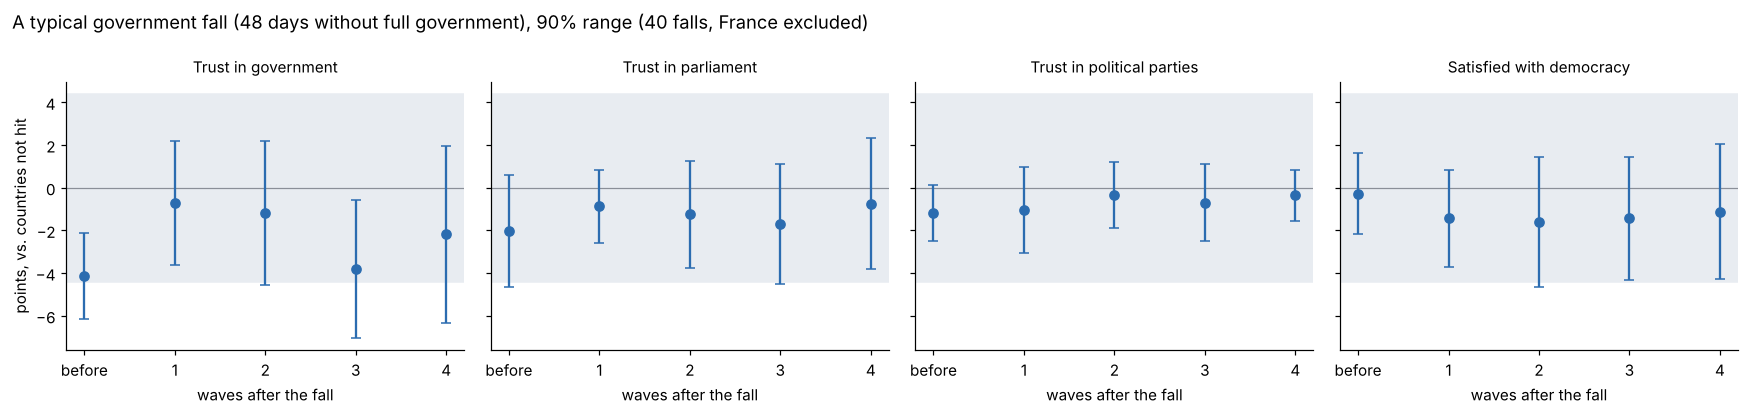

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (o, label) in zip(axes, OUTCOMES.items()):
    r = np.array([reading(o, h, TYPICAL['days'], TYPICAL['early'], TYPICAL['falls24']) for h in [0] + HORIZONS])
    ax.axhspan(-NOISE, NOISE, color=LIGHT, zorder=0)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.errorbar([0] + HORIZONS, r[:, 0], yerr=r[:, 2] * r[:, 1], fmt='o', color=BLUE, capsize=3)
    ax.set_xticks([0] + HORIZONS, ['before'] + [str(h) for h in HORIZONS])
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('waves after the fall')
axes[0].set_ylabel('points, vs. countries not hit')
fig.suptitle(f"A typical government fall ({TYPICAL['days']:.0f} days without full government), 90% range ({int(est.n_events.max())} falls, France excluded)", x=0.01, ha='left')
plt.tight_layout()
plt.show()

## 5. Effect per unit of each slider

The table the dashboard reads. For each outcome and horizon: the effect per unit of each slider and its 90% range. A slider's effect is *added* to the base effect of a fall, so **the reading for a scenario is the sum of the terms** (the dose-response chart below does this sum with its correct, joint range).

In [7]:
first = est[(est.horizon == 1)].copy()
first['Effect (90% range)'] = first.apply(lambda r: f"{r.estimate:+.1f} ({r.ci_low:+.1f} to {r.ci_high:+.1f})", axis=1)
tab = first.pivot_table(index='term', columns='outcome', values='Effect (90% range)', aggfunc='first')
tab = tab.reindex(EVENT_TERMS)[list(OUTCOMES)]
tab.index = [LABEL[i] for i in tab.index]
tab.columns = [OUTCOMES[c] for c in tab.columns]
print('First wave after the fall (h = 1), points:')
display(tab)

First wave after the fall (h = 1), points:


,Trust in government,Trust in parliament,Trust in political parties,Satisfied with democracy
A fall (base effect),-0.1 (-4.9 to +4.7),-0.7 (-4.2 to +2.9),-0.5 (-2.7 to +1.7),+0.3 (-2.6 to +3.3)
Per 100 days without full government,-0.0 (-1.3 to +1.3),-0.3 (-1.3 to +0.6),-0.1 (-0.6 to +0.5),+0.1 (-1.1 to +1.4)
Ends with an early election,+0.9 (-4.4 to +6.3),+1.1 (-2.6 to +4.9),+1.1 (-1.9 to +4.0),+1.0 (-2.2 to +4.2)
Per earlier fall in the past 24 months,-0.6 (-3.7 to +2.4),-0.0 (-3.0 to +2.9),-0.5 (-2.6 to +1.6),-1.8 (-4.0 to +0.3)


### Dose-response: days without a full government

The reading for a fall with *x* days without a full government (no early election, one earlier fall in 24 months, the typical case), first wave after. The range uses the joint uncertainty of the base effect and the slope. Ticks on the axis are the observed falls: the slider stops at the largest one, so the reading never goes beyond what the data have seen.

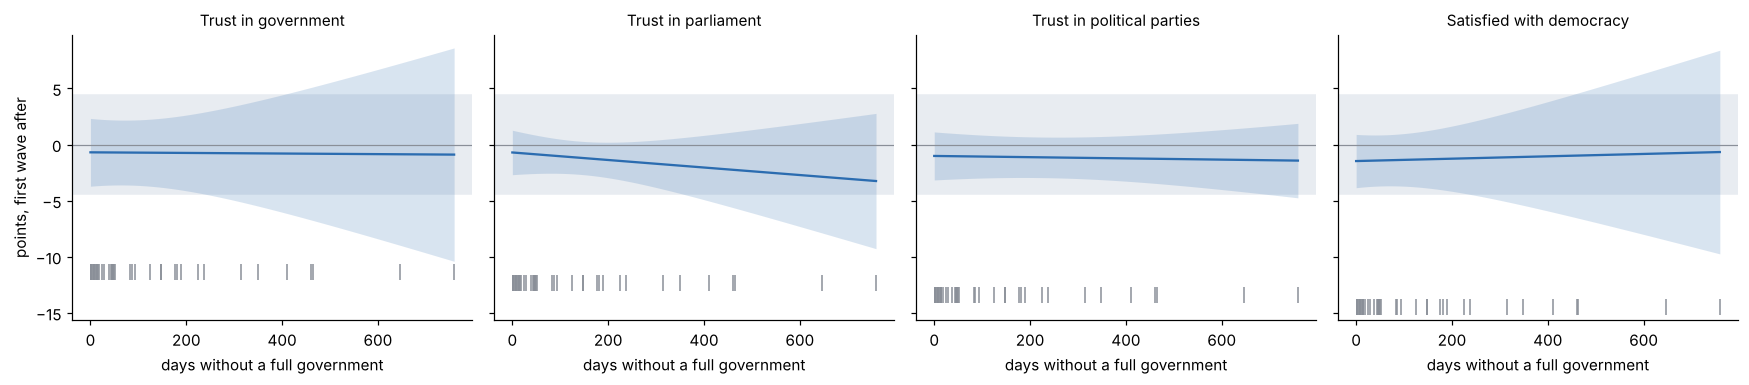

In [8]:
DAYS_MAX = falls[falls.iso3 != HELD_OUT].days_no_gov.max()
grid = np.linspace(0, DAYS_MAX, 60)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (o, label) in zip(axes, OUTCOMES.items()):
    r = np.array([reading(o, 1, d) for d in grid])
    ax.axhspan(-NOISE, NOISE, color=LIGHT, zorder=0)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.fill_between(grid, r[:, 0] - r[:, 2] * r[:, 1], r[:, 0] + r[:, 2] * r[:, 1], color=BLUE, alpha=0.18, lw=0)
    ax.plot(grid, r[:, 0], color=BLUE)
    ax.plot(falls[falls.iso3 != HELD_OUT].days_no_gov, np.full((falls.iso3 != HELD_OUT).sum(), ax.get_ylim()[0]), '|', color=GREY, ms=10)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('days without a full government')
axes[0].set_ylabel('points, first wave after')
plt.tight_layout()
plt.show()

## 6. Reliability

For the dashboard's *Reliability* block: how many past falls stand behind each estimate, whether a typical fall's effect can be told apart from zero and from survey noise, and whether the placebo is clean.

In [9]:
rel = []
for o, label in OUTCOMES.items():
    for h in HORIZONS:
        r = est[(est.outcome == o) & (est.horizon == h) & (est.term == 'fall')].iloc[0]
        m, se, c = reading(o, h, TYPICAL['days'], TYPICAL['early'], TYPICAL['falls24'])
        lo, hi = m - c * se, m + c * se
        if lo > 0 or hi < 0:
            verdict = 'range excludes zero' + ('' if abs(m) > NOISE else ', but smaller than survey noise')
        else:
            verdict = 'no detectable change'
        pm, pse, pc = reading(o, 0, TYPICAL['days'], TYPICAL['early'], TYPICAL['falls24'])
        rel.append({'Outcome': label, 'h': h, 'Falls': r.n_events, 'Country-waves': r.n_obs,
                    'Typical fall': f"{m:+.1f} ({lo:+.1f} to {hi:+.1f})", 'Reading': verdict,
                    'Placebo clean?': 'yes' if pm - pc * pse <= 0 <= pm + pc * pse else f'no ({pm:+.1f})'})
rel = pd.DataFrame(rel)
display(rel)

,Outcome,h,Falls,Country-waves,Typical fall,Reading,Placebo clean?
0,Trust in government,1,40,1153,-0.7 (-3.6 to +2.2),no detectable change,no (-4.2)
1,Trust in government,2,39,1127,-1.2 (-4.5 to +2.2),no detectable change,no (-4.2)
2,Trust in government,3,37,1101,-3.8 (-7.0 to -0.6),"range excludes zero, but smaller than survey noise",no (-4.2)
3,Trust in government,4,37,1075,-2.2 (-6.3 to +2.0),no detectable change,no (-4.2)
4,Trust in parliament,1,40,1127,-0.9 (-2.6 to +0.8),no detectable change,yes
5,Trust in parliament,2,39,1101,-1.2 (-3.7 to +1.2),no detectable change,yes
6,Trust in parliament,3,37,1075,-1.7 (-4.5 to +1.1),no detectable change,yes
7,Trust in parliament,4,37,1049,-0.7 (-3.8 to +2.3),no detectable change,yes
8,Trust in political parties,1,40,1026,-1.0 (-3.1 to +1.0),no detectable change,yes
9,Trust in political parties,2,39,1000,-0.3 (-1.9 to +1.2),no detectable change,yes


## 7. Check on France, out of sample

The model above never saw France. Here it predicts France's two recent falls, and the prediction is compared with what happened.

- **Barnier, 4 Dec 2024** (censure motion): next full government 9 days later (Bayrou appointed 13 Dec); no early election within a year.
- **Bayrou, 8 Sep 2025** (lost a confidence vote): Lecornu appointed the next day, government formed 5 Oct, resigned 6 Oct, reappointed 10 Oct with a government on 12 Oct, so **34 days** to a full government; no early election. PPEG codes this ending as a resignation, so it is added here by hand (dates from news reports; to check against the *Journal officiel*).

**Predicted** = the effect of a fall with France's slider values, with a 90% range for *one* episode (the model's uncertainty plus the spread of individual episodes). **Actual** = France's change minus what the model attributes to the rest (wave effect, the economy, the trend), i.e. the part a fall would have to explain.

In [10]:
FR_EVENTS = [
    {'episode': 'France 2024–25 (Barnier)', 'event_date': pd.Timestamp('2024-12-04'), 'days': 9, 'early': 0,
     'falls24': float(endings.loc[endings.episode_id == 'FRA_2024_25_instability', 'falls_24m'].iloc[0])},
    {'episode': 'France 2025 (Bayrou)', 'event_date': pd.Timestamp('2025-09-08'), 'days': 34, 'early': 0,
     'falls24': float(endings.loc[endings.episode_id == 'FRA_202509_Bayrou', 'falls_24m'].iloc[0])},
]

def residual_part(model, row_x, xbar_country=True):
    # Prediction of everything except the fall terms, for a country the model did not see (average country effect).
    s, X, b, V, u, G = model
    cfe = [c for c in b.index if c.startswith('c_')]
    x = row_x.reindex(b.index).fillna(0.0)
    for term in EVENT_TERMS:
        x[term] = 0.0
    other = float(x @ b)
    if xbar_country:
        other += b[cfe].sum() / (len(cfe) + 1)   # average country effect (the dropped country is 0)
    return other

def predict_episode(model, outcome, h, iso3, date, days, early, falls24, exclude_in_build=()):
    # Predicted range and actual 'unexplained' change for one fall in one country.
    s, X, b, V, u, G = model
    full = build_sample(outcome, h, exclude=exclude_in_build)
    full = full[full.iso3 == iso3]
    row = full[full.date >= date].head(1)
    if row.empty:
        return None
    Xr = design(pd.concat([s.head(1), row]))  # same column set
    Xr = Xr.reindex(columns=b.index, fill_value=0.0).iloc[[-1]]
    xr = Xr.iloc[0].copy()
    xr[[c for c in b.index if c.startswith('w_')]] = 0.0
    wave_col = f"w_{row.wave.iloc[0]}"
    if wave_col in b.index:
        xr[wave_col] = 1.0
    xr[[c for c in b.index if c.startswith('c_')]] = 0.0
    actual = row.dy.iloc[0] - residual_part(model, xr)
    m, se, crit = reading(outcome, h, days, early, falls24, model)
    sigma = np.sqrt(np.sum(u ** 2) / (len(u) - len(b)))
    half = crit * np.sqrt(se ** 2 + sigma ** 2)
    return {'predicted': m, 'pred_low': m - half, 'pred_high': m + half, 'actual': actual,
            'observed_change': row.dy.iloc[0], 'wave': row.wave.iloc[0], 'wave_date': row.date.iloc[0]}

fc = []
for ev in FR_EVENTS:
    for o in OUTCOMES:
        for h in HORIZONS:
            if ev['episode'].endswith('(Barnier)') and h > 1:
                continue   # later waves already contain the Bayrou fall
            r = predict_episode(models[(o, h)], o, h, 'FRA', ev['event_date'], ev['days'], ev['early'], ev['falls24'])
            if r:
                fc.append({'scenario': 'S1', 'episode': ev['episode'], 'outcome': o, 'horizon': h, **r})
france_check = pd.DataFrame(fc)
france_check['inside'] = france_check.actual.between(france_check.pred_low, france_check.pred_high)
show = france_check.assign(Outcome=france_check.outcome.map(OUTCOMES),
                           Predicted=lambda d: d.apply(lambda r: f"{r.predicted:+.1f} ({r.pred_low:+.1f} to {r.pred_high:+.1f})", axis=1),
                           Actual=lambda d: d.actual.round(1), **{'Raw change': france_check.observed_change.round(1)})
display(show[['episode', 'Outcome', 'horizon', 'Predicted', 'Actual', 'Raw change', 'inside']])

,episode,Outcome,horizon,Predicted,Actual,Raw change,inside
0,France 2024–25 (Barnier),Trust in government,1,-1.3 (-12.8 to +10.2),2.9,5.4,True
1,France 2024–25 (Barnier),Trust in parliament,1,-0.8 (-10.8 to +9.2),0.3,1.8,True
2,France 2024–25 (Barnier),Trust in political parties,1,-1.5 (-9.8 to +6.8),-0.6,-2.3,True
3,France 2024–25 (Barnier),Satisfied with democracy,1,-3.3 (-12.8 to +6.3),5.6,10.9,True
4,France 2025 (Bayrou),Trust in government,1,-2.6 (-16.6 to +11.4),-10.9,-14.3,True
5,France 2025 (Bayrou),Trust in parliament,1,-1.0 (-14.1 to +12.1),-10.5,-12.8,True
6,France 2025 (Bayrou),Trust in political parties,1,-2.6 (-13.2 to +8.1),-4.5,-3.3,True
7,France 2025 (Bayrou),Satisfied with democracy,1,-6.9 (-18.4 to +4.6),-8.7,-13.5,True


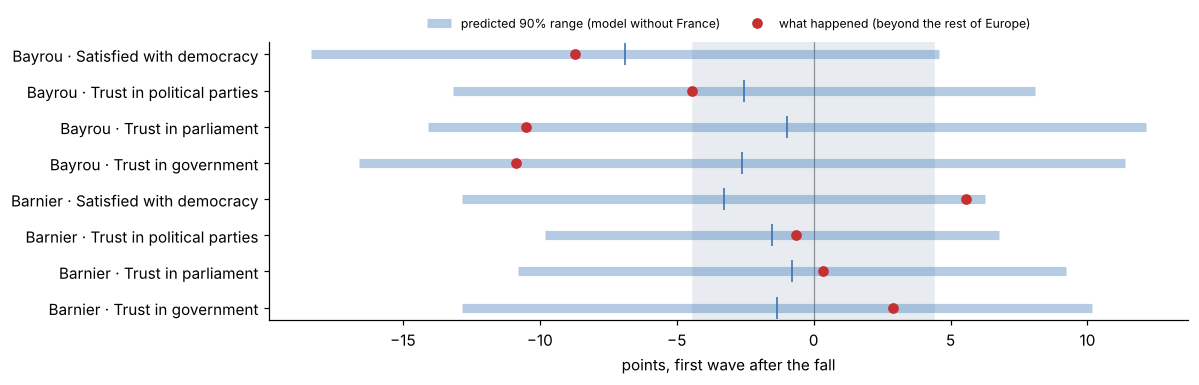

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.6))
d = france_check[france_check.horizon == 1].reset_index(drop=True)
ypos = np.arange(len(d))
ax.axvspan(-NOISE, NOISE, color=LIGHT, zorder=0)
ax.axvline(0, color=GREY, lw=0.8)
ax.hlines(ypos, d.pred_low, d.pred_high, color=BLUE, lw=6, alpha=0.35, label='predicted 90% range (model without France)')
ax.plot(d.predicted, ypos, '|', color=BLUE, ms=14)
ax.plot(d.actual, ypos, 'o', color=RED, label='what happened (beyond the rest of Europe)')
ax.set_yticks(ypos, [f"{e.split(' (')[1][:-1]} · {OUTCOMES[o]}" for e, o in zip(d.episode, d.outcome)])
ax.set_xlabel('points, first wave after the fall')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

## 8. Back-test: leave one country out

For every country with a fall, the model is estimated **without that country**, then asked to predict each of its falls (90% range for one episode). If the ranges are well calibrated, about **9 in 10** real outcomes fall inside them (*coverage*, Addendum point 3). Leaving out the whole country, not just the episode, is the stricter version: the model cannot learn a country's habits from its other falls.

Hungary and Poland, the back-test cases in KR 4.3, belong to S5 (executive power) and are tested there.

In [12]:
bt = []
countries = sorted(falls.loc[falls.iso3 != HELD_OUT, 'iso3'].unique())
for o in OUTCOMES:
    for h in HORIZONS:
        for iso3 in countries:
            model = estimate(o, h, exclude=(HELD_OUT, iso3))
            for ev in falls[falls.iso3 == iso3].itertuples():
                r = predict_episode(model, o, h, iso3, ev.event_date, ev.days_no_gov, ev.early_election, ev.falls_24m,
                                    exclude_in_build=(HELD_OUT,))
                if r:
                    bt.append({'scenario': 'S1', 'episode': ev.episode_id, 'outcome': o, 'horizon': h, **r})
backtest = pd.DataFrame(bt)
backtest['inside'] = backtest.actual.between(backtest.pred_low, backtest.pred_high)
cov = backtest.pivot_table(index='outcome', columns='horizon', values='inside', aggfunc='mean').round(2)
cov.index = [OUTCOMES[i] for i in cov.index]
cov.columns = [f'h = {c}' for c in cov.columns]
print(f"{backtest.episode.nunique()} episodes, {len(backtest)} predictions. Share of real outcomes inside the 90% range (target about 0.90):")
display(cov)
print(f"Overall coverage: {backtest.inside.mean():.2f}")

41 episodes, 628 predictions. Share of real outcomes inside the 90% range (target about 0.90):
Overall coverage: 0.87


,h = 1,h = 2,h = 3,h = 4
Satisfied with democracy,0.88,0.88,0.87,0.89
Trust in government,0.80,0.82,0.84,0.79
Trust in parliament,0.88,0.90,0.84,0.84
Trust in political parties,0.90,0.92,0.89,0.89


## 9. Tables for the dashboard

Three files in `outputs/model/`, in the format of the specification (section 7) and the Addendum (section 3):

- `s1_effects.csv`: one row per parameter × outcome × horizon: effect per unit, 90% range, number of falls, `estimated_without = FRA`. The *days* slider is stored **per day** (the model uses hundreds of days).
- `s1_france_check.csv`: France's falls, predicted without France, against what happened.
- `s1_backtest.csv`: every leave-one-country-out prediction.
- `s1_threshold.txt`: the rule that defines the shock and who set it.

In [13]:
PARAM = {'fall': ('fall', 1), 'days': ('days_no_gov', 100), 'early_election': ('early_election', 1), 'falls_24m': ('falls_24m', 1)}
eff = est[est.horizon > 0].copy()
eff['parameter'] = eff.term.map(lambda t: PARAM[t][0])
scale = eff.term.map(lambda t: PARAM[t][1])
for c in ['estimate', 'ci_low', 'ci_high']:
    eff[c] = eff[c] / scale
effects = eff.rename(columns={'estimate': 'effect_per_unit'}).assign(shock='S1', estimated_without=HELD_OUT)[
    ['shock', 'parameter', 'outcome', 'horizon', 'effect_per_unit', 'ci_low', 'ci_high', 'n_events', 'n_obs', 'estimated_without']]
effects.round(4).to_csv(OUT / 's1_effects.csv', index=False)
for df_, name in [(france_check, 's1_france_check.csv'), (backtest, 's1_backtest.csv')]:
    df_.assign(wave_date=df_.wave_date.dt.strftime('%Y-%m-%d')).round(3).to_csv(OUT / name, index=False)
(OUT / 's1_threshold.txt').write_text(
    "S1 government collapse. Rule: early cabinet end through coalition break-up or a lost parliamentary vote "
    "(PPEG termination codes Diss and LoPS, as CPDS codes 4-5), dated and confirmed by the team's case review "
    "(data/reference/s1_verified_events.csv, s1_researched_dates.csv, 15 Nov 2026). Set by: PPEG coding plus team review. "
    "No numeric threshold. Estimated without France (Addendum, 21 Nov 2026).\n", encoding='utf-8')
print('Wrote', ', '.join(p.name for p in sorted(OUT.glob('s1_*'))))
display(effects[(effects.horizon == 1)].round(3).head(8))

Wrote s1_backtest.csv, s1_effects.csv, s1_france_check.csv, s1_threshold.txt


,shock,parameter,outcome,horizon,effect_per_unit,ci_low,ci_high,n_events,n_obs,estimated_without
4,S1,fall,trust_gov,1,-0.057,-4.850,4.736,40,1153,FRA
5,S1,days_no_gov,trust_gov,1,-0.000,-0.013,0.013,40,1153,FRA
6,S1,early_election,trust_gov,1,0.941,-4.420,6.302,40,1153,FRA
7,S1,falls_24m,trust_gov,1,-0.638,-3.701,2.425,40,1153,FRA
24,S1,fall,trust_parl,1,-0.662,-4.175,2.851,40,1127,FRA
25,S1,days_no_gov,trust_parl,1,-0.003,-0.013,0.006,40,1127,FRA
26,S1,early_election,trust_parl,1,1.120,-2.628,4.867,40,1127,FRA
27,S1,falls_24m,trust_parl,1,-0.046,-3.021,2.929,40,1127,FRA


## 10. What this says, and what it does not

In [14]:
def fmt(o, h):
    m, se, c = reading(o, h, TYPICAL['days'], TYPICAL['early'], TYPICAL['falls24'])
    return f"{m:+.1f} points (90% range {m - c * se:+.1f} to {m + c * se:+.1f})"

lines = ['**What the panel says**', '']
n = int(est[est.horizon == 1].n_events.max())
lines.append(f"- **{n} government falls** in {falls[falls.iso3 != HELD_OUT].iso3.nunique()} EU countries since 2005 stand behind the estimates (France excluded).")
for o, label in OUTCOMES.items():
    r = rel[(rel.Outcome == label) & (rel.h == 1)].iloc[0]
    r3 = rel[(rel.Outcome == label) & (rel.h == 3)].iloc[0]
    lines.append(f"- **{label}**, typical fall: first wave after {fmt(o, 1)}, *{r.Reading}*; third wave after {fmt(o, 3)}, *{r3.Reading}*.")
pl = rel[rel.h == 1][['Outcome', 'Placebo clean?']]
bad = pl[pl['Placebo clean?'] != 'yes']
lines.append("- **Placebo:** " + ('clean for every outcome: trust was not already moving before the falls.' if bad.empty
             else 'not clean for ' + ', '.join(f"{o} ({p.split('(')[1][:-1]} points in the wave before the fall)" for o, p in zip(bad.Outcome, bad['Placebo clean?']))
             + ': trust drops *before* governments fall, so the fall itself adds little on top. For the dashboard, the honest reading is that the loss of trust and the fall arrive together.'))
d1 = est[(est.horizon == 1) & (est.term == 'days')]
sig = d1[(d1.ci_low > 0) | (d1.ci_high < 0)]
lines.append("- **Length of the crisis:** " + ('the days-without-government slope is distinguishable from zero for ' + ', '.join(OUTCOMES[o] for o in sig.outcome) + '.'
             if len(sig) else 'no outcome shows a slope in the days without government that can be told apart from zero.'))
lines.append(f"- **Back-test:** {backtest.inside.mean():.0%} of {len(backtest)} leave-one-country-out predictions fall inside their 90% range (target about 90%).")
fr1 = france_check[france_check.horizon == 1]
lines.append(f"- **France, out of sample:** {int(fr1.inside.sum())} of {len(fr1)} first-wave readings fall inside the predicted range.")
for ep in fr1.episode.unique():
    g = fr1[(fr1.episode == ep) & (fr1.outcome == 'trust_gov')].iloc[0]
    lines.append(f"  - {ep}: trust in government moved {g.actual:+.1f} beyond the rest of Europe; the model's range was {g.pred_low:+.1f} to {g.pred_high:+.1f}.")
display(Markdown('\n'.join(lines)))

**What the panel says**

- **40 government falls** in 22 EU countries since 2005 stand behind the estimates (France excluded).
- **Trust in government**, typical fall: first wave after -0.7 points (90% range -3.6 to +2.2), *no detectable change*; third wave after -3.8 points (90% range -7.0 to -0.6), *range excludes zero, but smaller than survey noise*.
- **Trust in parliament**, typical fall: first wave after -0.9 points (90% range -2.6 to +0.8), *no detectable change*; third wave after -1.7 points (90% range -4.5 to +1.1), *no detectable change*.
- **Trust in political parties**, typical fall: first wave after -1.0 points (90% range -3.1 to +1.0), *no detectable change*; third wave after -0.7 points (90% range -2.5 to +1.1), *no detectable change*.
- **Satisfied with democracy**, typical fall: first wave after -1.4 points (90% range -3.7 to +0.9), *no detectable change*; third wave after -1.4 points (90% range -4.3 to +1.5), *no detectable change*.
- **Placebo:** not clean for Trust in government (-4.2 points in the wave before the fall): trust drops *before* governments fall, so the fall itself adds little on top. For the dashboard, the honest reading is that the loss of trust and the fall arrive together.
- **Length of the crisis:** no outcome shows a slope in the days without government that can be told apart from zero.
- **Back-test:** 87% of 628 leave-one-country-out predictions fall inside their 90% range (target about 90%).
- **France, out of sample:** 8 of 8 first-wave readings fall inside the predicted range.
  - France 2024–25 (Barnier): trust in government moved +2.9 beyond the rest of Europe; the model's range was -12.8 to +10.2.
  - France 2025 (Bayrou): trust in government moved -10.9 beyond the rest of Europe; the model's range was -16.6 to +11.4.

**What it cannot show**

- **Not a cause.** Wave effects remove Europe-wide moves and country effects a country's usual drift, but a fall and a drop in trust can share a cause (a scandal, a budget fight) that the model does not see.
- **Timing is coarse.** Eurobarometer asks twice a year, so *h* = 1 can be one to six months after the fall. Fieldwork centres are used to place each fall.
- **Ranges are for an average episode.** The predicted ranges in sections 7–8 add the spread of individual episodes; the effects table (section 5) is the average effect, which is narrower.
- **2005 onwards.** The 1997–2004 waves are in the panel but falls before 2005 are not yet coded, so those waves are not used.
- **Not yet in:** months to the next scheduled election (needs term lengths); turnout and fragmentation at the next election (secondary outputs).
- **France's Bayrou fall** is added by hand (PPEG codes it as a resignation); its dates are from news reports.